# Cấu hình và thư viện

In [7]:
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

SEED = 42
DATA_DIR = "./cifar-10"
EPOCHS = 16
BATCH_SIZE = 64
LR = 1e-3

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(2, os.cpu_count() or 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device = {DEVICE} | Seed = {SEED}")

PyTorch 2.15.0+cpu | Device = cpu | Seed = 42


# Đọc trainLabels.csv, nạp ảnh từ train và chia Train / Val / Test

In [8]:
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
label_to_idx = {name: idx for idx, name in enumerate(CLASS_NAMES)}

def sample_by_class(y, n_train, n_val, n_test=None, seed=42):
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for label in np.unique(y):
        ids = np.where(y == label)[0]
        rng.shuffle(ids)
        end_test = len(ids) if n_test is None else n_train + n_val + n_test
        assert len(ids) >= end_test
        tr.extend(ids[:n_train])
        va.extend(ids[n_train:n_train + n_val])
        te.extend(ids[n_train + n_val:end_test])
    return np.array(tr), np.array(va), np.array(te)

def load_selected_images(img_ids, folder):
    arr = np.empty((len(img_ids), 32, 32, 3), dtype=np.uint8)
    for i, img_id in enumerate(img_ids):
        path = os.path.join(folder, f"{img_id}.png")
        with Image.open(path) as img:
            arr[i] = np.asarray(img.convert("RGB"), dtype=np.uint8)
    return torch.tensor(arr, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0

df_labels = pd.read_csv(os.path.join(DATA_DIR, "trainLabels.csv"))
all_ids = df_labels["id"].to_numpy()
labels = df_labels["label"].map(label_to_idx).to_numpy(dtype=np.int64)

if torch.cuda.is_available():
    it, iv, ie = sample_by_class(labels, n_train=3500, n_val=500, n_test=1000, seed=SEED)
else:
    it, iv, ie = sample_by_class(labels, n_train=500, n_val=100, n_test=200, seed=SEED)

train_folder = os.path.join(DATA_DIR, "train")
if os.path.isdir(os.path.join(train_folder, "train")):
    train_folder = os.path.join(train_folder, "train")

X_train = load_selected_images(all_ids[it], train_folder)
X_val = load_selected_images(all_ids[iv], train_folder)
X_test = load_selected_images(all_ids[ie], train_folder)

y_train = torch.tensor(labels[it], dtype=torch.long)
y_val = torch.tensor(labels[iv], dtype=torch.long)
y_test = torch.tensor(labels[ie], dtype=torch.long)

mu = float(X_train.mean())
sigma = float(X_train.std().clamp_min(1e-6))
print(f"Train/Val/Test: {len(y_train)}/{len(y_val)}/{len(y_test)}")
print(f"Tensor ảnh = {tuple(X_train.shape)}; giá trị gốc trong [0, 1]")
print(f"Mean train = {mu:.4f}; std train = {sigma:.4f}; lớp = {len(CLASS_NAMES)}")
print("Số lượng từng lớp (train):", torch.bincount(y_train).tolist())

Train/Val/Test: 5000/1000/2000
Tensor ảnh = (5000, 3, 32, 32); giá trị gốc trong [0, 1]
Mean train = 0.4700; std train = 0.2510; lớp = 10
Số lượng từng lớp (train): [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


# Hiển thị 10 ảnh đại diện của 10 lớp

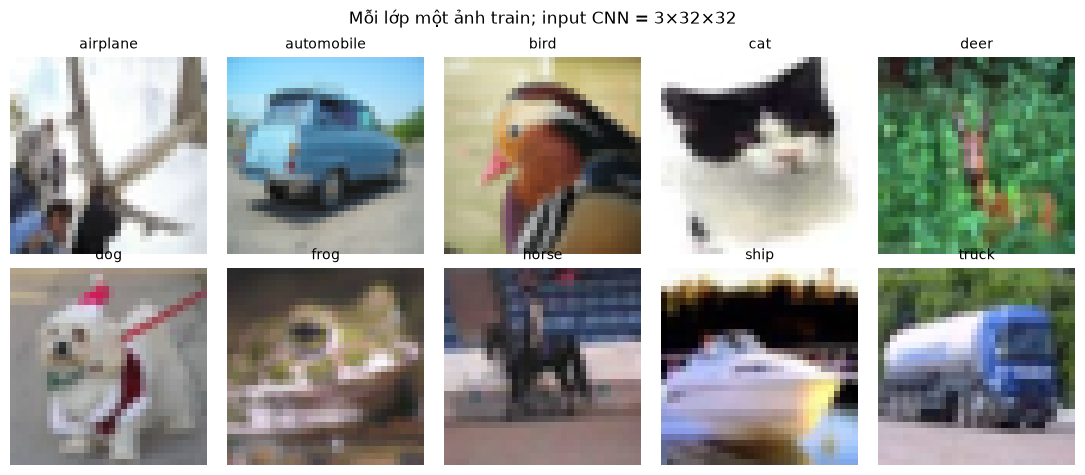

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for c, ax in enumerate(axes.flat):
    idx = int((y_train == c).nonzero(as_tuple=True)[0][0])
    ax.imshow(X_train[idx].permute(1, 2, 0).clamp(0, 1))
    ax.set_title(CLASS_NAMES[c], fontsize=10)
    ax.axis("off")
fig.suptitle("Mỗi lớp một ảnh train; input CNN = 3×32×32")
plt.tight_layout()
plt.show()

# Data Augmentation và DataLoader

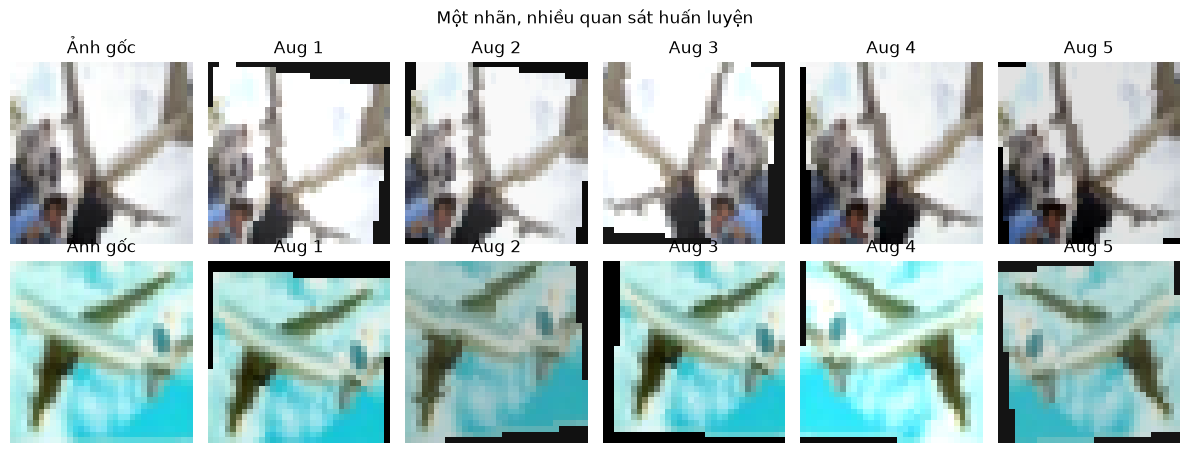

Một mini-batch: (64, 3, 32, 32) | nhãn: (64,)


In [10]:
class ImageTensorDataset(Dataset):
    def __init__(self, x, y, augment=False):
        self.x, self.y = x, y
        self.augment = augment
        self.augmenter = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.95, 1.05)),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
        ])

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        image = self.x[idx]
        if self.augment:
            image = self.augmenter(image).clamp(0, 1)
        image = (image - mu) / sigma
        return image, self.y[idx]

def loader(x, y, train=False, augment=False, batch_size=BATCH_SIZE):
    return DataLoader(ImageTensorDataset(x, y, augment=augment),
                      batch_size=batch_size, shuffle=train, num_workers=0)

train_clean_loader = loader(X_train, y_train, train=False)
train_plain_loader = loader(X_train, y_train, train=True)
train_aug_loader   = loader(X_train, y_train, train=True, augment=True)
val_loader         = loader(X_val, y_val)
test_loader        = loader(X_test, y_test, batch_size=128)

seed_all()
fig, axs = plt.subplots(2, 6, figsize=(12, 4.6))
for row, idx in enumerate([0, 1]):
    original = X_train[idx]
    axs[row, 0].imshow(original.permute(1, 2, 0).clamp(0, 1))
    axs[row, 0].set_title("Ảnh gốc")
    for col in range(1, 6):
        a = train_aug_loader.dataset.augmenter(original).clamp(0, 1)
        axs[row, col].imshow(a.permute(1, 2, 0).clamp(0, 1))
        axs[row, col].set_title(f"Aug {col}")
    for ax in axs[row]:
        ax.axis("off")
plt.suptitle("Một nhãn, nhiều quan sát huấn luyện")
plt.tight_layout()
plt.show()
xb, yb = next(iter(train_plain_loader))
print("Một mini-batch:", tuple(xb.shape), "| nhãn:", tuple(yb.shape))

# Kiến trúc LeNet (3 kênh)

In [11]:
class LeNet(nn.Module):
    def __init__(self, in_channels=3, activation="tanh", pool="avg", batchnorm=False, dropout=0.0, n_classes=10):
        super().__init__()
        make_act = nn.Tanh if activation == "tanh" else nn.ReLU
        make_pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 6, kernel_size=5),
            nn.BatchNorm2d(6) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.BatchNorm2d(16) if batchnorm else nn.Identity(),
            make_act(), make_pool(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 5 * 5, 120), make_act(), nn.Dropout(dropout),
            nn.Linear(120, 84), make_act(), nn.Dropout(dropout), nn.Linear(84, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline = LeNet()
with torch.no_grad():
    out = baseline(torch.zeros(4, 3, 32, 32))
print("LeNet output:", tuple(out.shape), "| tham số:", f"{count_params(baseline):,}")
print("LeNet classifier:", baseline.classifier)

LeNet output: (4, 10) | tham số: 62,006
LeNet classifier: Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=400, out_features=120, bias=True)
  (2): Tanh()
  (3): Dropout(p=0.0, inplace=False)
  (4): Linear(in_features=120, out_features=84, bias=True)
  (5): Tanh()
  (6): Dropout(p=0.0, inplace=False)
  (7): Linear(in_features=84, out_features=10, bias=True)
)


# Ba kiến trúc Modern CNN (VGGTiny, InceptionTiny, ResNetTiny)

In [12]:
def vgg_block(cin, cout, nconv=2):
    layers = []
    for j in range(nconv):
        layers += [nn.Conv2d(cin if j == 0 else cout, cout, 3, padding=1, bias=False),
                   nn.BatchNorm2d(cout), nn.ReLU()]
    return nn.Sequential(*layers, nn.MaxPool2d(2))

class VGGTiny(nn.Module):
    def __init__(self, in_channels=3, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(vgg_block(in_channels, 16), vgg_block(16, 32), vgg_block(32, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.25),
                                  nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

class InceptionBlock(nn.Module):
    def __init__(self, cin, branch_channels):
        super().__init__()
        c = branch_channels
        def cbr(a, b, k, p=0):
            return [nn.Conv2d(a, b, k, padding=p, bias=False), nn.BatchNorm2d(b), nn.ReLU()]
        self.b1 = nn.Sequential(*cbr(cin, c, 1))
        self.b3 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 3, p=1))
        self.b5 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 5, p=2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), *cbr(cin, c, 1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class InceptionTiny(nn.Module):
    def __init__(self, in_channels=3, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            InceptionBlock(16, 8), nn.MaxPool2d(2),
            InceptionBlock(32, 16), nn.MaxPool2d(2),
            InceptionBlock(64, 16))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.25), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

class ResidualBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.residual = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if cin == cout and stride == 1 else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout)))
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.residual(x) + self.skip(x))

class ResNetTiny(nn.Module):
    def __init__(self, in_channels=3, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_channels, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        self.blocks = nn.Sequential(ResidualBlock(16, 16), ResidualBlock(16, 32, stride=2),
                                    ResidualBlock(32, 32), ResidualBlock(32, 64, stride=2), ResidualBlock(64, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))

models_for_shape = {"LeNet": LeNet(), "VGG-tiny": VGGTiny(),
                    "Inception-tiny": InceptionTiny(), "ResNet-tiny": ResNetTiny()}
shape_rows = []
for name, net in models_for_shape.items():
    with torch.no_grad():
        output = net.eval()(torch.zeros(2, 3, 32, 32))
    shape_rows.append(dict(model=name, logits_shape=str(tuple(output.shape)),
                           params=count_params(net)))
pd.DataFrame(shape_rows)

,model,logits_shape,params
0,LeNet,"(2, 10)",62006
1,VGG-tiny,"(2, 10)",77114
2,Inception-tiny,"(2, 10)",27850
3,ResNet-tiny,"(2, 10)",170586


# Bộ hàm huấn luyện, đánh giá và phân tích lỗi

In [17]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    n_correct = 0
    n_samples = 0

    for x, y in dataloader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (logits.argmax(dim=1) == y).sum().item()
        n_samples += batch_size

    if n_samples == 0:
        raise ValueError("Train DataLoader không được rỗng")
    return {"loss": total_loss / n_samples,
            "accuracy": n_correct / n_samples,
            "n_samples": n_samples}

@torch.inference_mode()
def evaluate(model, dataloader, criterion, device, return_predictions=False):
    model.eval()
    total_loss = 0.0
    n_correct = 0
    n_samples = 0
    y_true, y_pred = [], []

    for x, y in dataloader:
        x = x.to(device)
        y = y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        preds = logits.argmax(dim=1)

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        n_correct += (preds == y).sum().item()
        n_samples += batch_size
        if return_predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    if n_samples == 0:
        raise ValueError("Eval DataLoader không được rỗng")
    metrics = {"loss": total_loss / n_samples,
               "accuracy": n_correct / n_samples,
               "n_samples": n_samples}
    if return_predictions:
        metrics["y_true"] = np.asarray(y_true, dtype=np.int64)
        metrics["y_pred"] = np.asarray(y_pred, dtype=np.int64)
    return metrics

def test_model(model, dataloader, criterion, device, class_names):
    raw = evaluate(model, dataloader, criterion, device, return_predictions=True)
    labels = list(range(len(class_names)))
    cm = confusion_matrix(raw["y_true"], raw["y_pred"], labels=labels)
    report = classification_report(raw["y_true"], raw["y_pred"],
                                   labels=labels, target_names=class_names,
                                   zero_division=0)
    return {"loss": raw["loss"], "accuracy": raw["accuracy"],
            "n_samples": raw["n_samples"],
            "y_true": raw["y_true"], "y_pred": raw["y_pred"],
            "confusion_matrix": cm, "classification_report": report}

In [18]:
criterion = nn.CrossEntropyLoss()
RESULTS, HISTORIES, BEST_MODELS = [], {}, {}
VAL_ANALYSES = {}

def fit_model(model, train_loader, train_monitor_loader, val_loader,
              optimizer, criterion, device, epochs, run_name):
    history = []
    best_val_loss, best_state, best_epoch = float("inf"), None, 0
    print("epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best")
    print("-" * 78)

    for epoch in range(1, epochs + 1):
        opt = train_one_epoch(model, train_loader, optimizer, criterion, device)
        train = evaluate(model, train_monitor_loader, criterion, device)
        val = evaluate(model, val_loader, criterion, device)
        history.append({"epoch": epoch, "opt_loss": opt["loss"],
                        "opt_acc": opt["accuracy"],
                        "train_loss": train["loss"], "train_acc": train["accuracy"],
                        "val_loss": val["loss"], "val_acc": val["accuracy"]})

        improved = val["loss"] < best_val_loss
        if improved:
            best_val_loss = val["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        print(f"{epoch:02d}/{epochs:02d} | {opt['loss']:.4f}   | "
              f"{train['loss']:.4f}     | {train['accuracy']:.2%}  | "
              f"{val['loss']:.4f}   | {val['accuracy']:.2%}  | {'*' if improved else ''}",
              flush=True)

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def plot_single_run(name, history):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    axes[0].plot(history.epoch, history.train_acc * 100, label="Train sạch")
    axes[0].plot(history.epoch, history.val_acc * 100, label="Validation")
    axes[1].plot(history.epoch, history.train_loss, label="Train sạch")
    axes[1].plot(history.epoch, history.val_loss, label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend()
    fig.suptitle(f"Learning curves: {name}", weight="bold")
    plt.tight_layout()
    plt.show()

def run_experiment(name, model_factory, use_aug=False, wd=0.0,
                   epochs=EPOCHS, seed=SEED, show_plot=True):
    if name in HISTORIES:
        raise ValueError(f"Tên thí nghiệm đã tồn tại: {name}. Run all để làm mới.")
    seed_all(seed)
    model = model_factory().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=wd)
    dl_train = train_aug_loader if use_aug else train_plain_loader
    start = time.perf_counter()
    print(f"\n=== {name} ===")
    print(f"params={count_params(model):,} | augmentation={use_aug} | "
          f"weight_decay={wd:g} | lr={LR} | epochs={epochs}")
    model, history, best_epoch = fit_model(
        model, dl_train, train_clean_loader, val_loader,
        optimizer, criterion, DEVICE, epochs, run_name=name)
    seconds = time.perf_counter() - start
    train = evaluate(model, train_clean_loader, criterion, DEVICE)
    val = evaluate(model, val_loader, criterion, DEVICE)
    row = {"model": name, "parameters": count_params(model),
           "best_epoch": best_epoch, "train_acc": train["accuracy"],
           "val_acc": val["accuracy"], "val_loss": val["loss"],
           "gap": train["accuracy"] - val["accuracy"], "seconds": round(seconds, 2)}
    HISTORIES[name] = history
    BEST_MODELS[name] = copy.deepcopy(model).cpu()
    RESULTS.append(row)
    print(f"\nCHECKPOINT được chọn: epoch {best_epoch:02d} | "
          f"train_acc={train['accuracy']:.2%} | val_acc={val['accuracy']:.2%} | "
          f"val_loss={val['loss']:.4f} | gap={row['gap']:+.2%}")
    if show_plot:
        plot_single_run(name, history)

    analysis = analyze_validation_errors(
        model, val_loader, CLASS_NAMES, DEVICE,
        mean=mu, std=sigma, run_name=name, max_examples=6, show_plot=show_plot)
    row["val_errors"] = analysis["n_errors"]
    VAL_ANALYSES[name] = analysis
    return row

In [19]:
@torch.inference_mode()
def collect_validation_predictions(model, dataloader, device):
    model.eval()
    records, stored_images = [], []
    sample_index = 0

    for images, labels in dataloader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)
        p_true = probabilities.gather(1, labels.to(device).unsqueeze(1)).squeeze(1)

        labels_cpu = labels.cpu().tolist()
        preds_cpu = predictions.cpu().tolist()
        confidences = confidence.cpu().tolist()
        p_true_values = p_true.cpu().tolist()
        stored_images.append(images.detach().cpu().clone())

        for true_label, pred_label, score, true_score in zip(
            labels_cpu, preds_cpu, confidences, p_true_values
        ):
            records.append({
                "sample_index": sample_index,
                "true_label": int(true_label),
                "pred_label": int(pred_label),
                "confidence": float(score),
                "p_true": float(true_score),
                "correct": int(true_label) == int(pred_label),
            })
            sample_index += 1

    if not records:
        raise ValueError("DataLoader validation không được rỗng")
    return pd.DataFrame(records), torch.cat(stored_images, dim=0)

def plot_misclassified_images(details, images, class_names, *,
                              mean=0.0, std=1.0, max_examples=6,
                              hardest_first=True, title="Validation"):
    wrong = details.loc[~details["correct"]].sort_values(
        "confidence", ascending=not hardest_first).head(max_examples)
    if wrong.empty:
        print("Không có mẫu validation dự đoán sai để hiển thị.")
        return

    ncols = min(3, len(wrong))
    nrows = (len(wrong) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")

    for ax, sample in zip(axes.ravel(), wrong.itertuples(index=False)):
        index = int(sample.sample_index)
        image = (images[index] * std + mean).clamp(0, 1)
        if image.shape[0] == 1:
            ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
        elif image.shape[0] == 3:
            ax.imshow(image.permute(1, 2, 0))
        else:
            raise ValueError("Ví dụ minh họa hiện hỗ trợ ảnh 1 hoặc 3 kênh")
        ax.set_title(
            f"Mẫu #{index} | Thật: {class_names[sample.true_label]} "
            f"→ Dự đoán: {class_names[sample.pred_label]}\n"
            f"Confidence: {sample.confidence:.1%} | P(nhãn thật): {sample.p_true:.1%}",
            fontsize=9, color="firebrick")
    label = "Sai nhưng rất tự tin" if hardest_first else "Sai với confidence thấp"
    fig.suptitle(f"{title} — {label} (VALIDATION)", fontsize=12, weight="bold")
    plt.tight_layout()
    plt.show()

def analyze_validation_errors(model, dataloader, class_names, device, *,
                              mean=0.0, std=1.0, run_name="Model",
                              max_examples=6, show_plot=True):
    details, images = collect_validation_predictions(model, dataloader, device)
    wrong = details.loc[~details["correct"]].copy()
    n_total, n_errors = len(details), len(wrong)
    print(f"\n--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — {run_name} ---")
    print(f"Sai {n_errors}/{n_total} mẫu ({n_errors/n_total:.2%}); "
          f"đúng {(n_total-n_errors)/n_total:.2%}.")

    if n_errors:
        pairs = (wrong.groupby(["true_label", "pred_label"])
                 .size().sort_values(ascending=False).head(3))
        print("Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):")
        for (true_id, pred_id), count in pairs.items():
            print(f"  {class_names[true_id]} → {class_names[pred_id]}: {count} mẫu")
        print(f"Confidence trung bình của các mẫu sai: {wrong['confidence'].mean():.2%}")
    else:
        print("Không có cặp nhầm lẫn trong validation tại checkpoint này.")

    if show_plot and n_errors:
        plot_misclassified_images(
            details, images, class_names, mean=mean, std=std,
            max_examples=max_examples, hardest_first=True, title=run_name)

    return {"details": details, "images": images,
            "n_errors": n_errors, "n_total": n_total}

# Chạy riêng từng thí nghiệm E0–E4 và M1–M3

# 10


=== E0 LeNet Tanh+Avg ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.9937   | 1.8453     | 34.70%  | 1.8743   | 34.10%  | *
02/16 | 1.8236   | 1.7584     | 37.40%  | 1.8152   | 35.40%  | *
03/16 | 1.7536   | 1.6990     | 40.92%  | 1.7700   | 37.90%  | *
04/16 | 1.7034   | 1.6573     | 42.02%  | 1.7479   | 40.10%  | *
05/16 | 1.6567   | 1.5841     | 44.12%  | 1.7051   | 41.10%  | *
06/16 | 1.6196   | 1.5506     | 46.20%  | 1.6898   | 41.80%  | *
07/16 | 1.5560   | 1.4910     | 47.80%  | 1.6660   | 41.40%  | *
08/16 | 1.5066   | 1.4429     | 48.42%  | 1.6454   | 42.10%  | *
09/16 | 1.4434   | 1.3912     | 51.42%  | 1.6509   | 41.50%  | 
10/16 | 1.4101   | 1.3200     | 53.68%  | 1.6063   | 42.70%  | *
11/16 | 1.3426   | 1.2584     | 56.10%  | 1.5683   | 44.20%  | *
12/16 | 1.2846   | 1.2068     | 57.

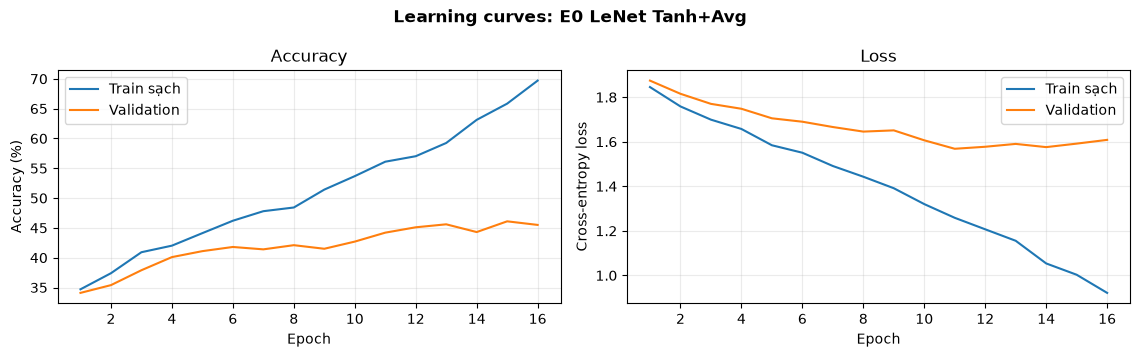


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E0 LeNet Tanh+Avg ---
Sai 558/1000 mẫu (55.80%); đúng 44.20%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  automobile → truck: 23 mẫu
  cat → dog: 22 mẫu
  truck → automobile: 21 mẫu
Confidence trung bình của các mẫu sai: 41.86%


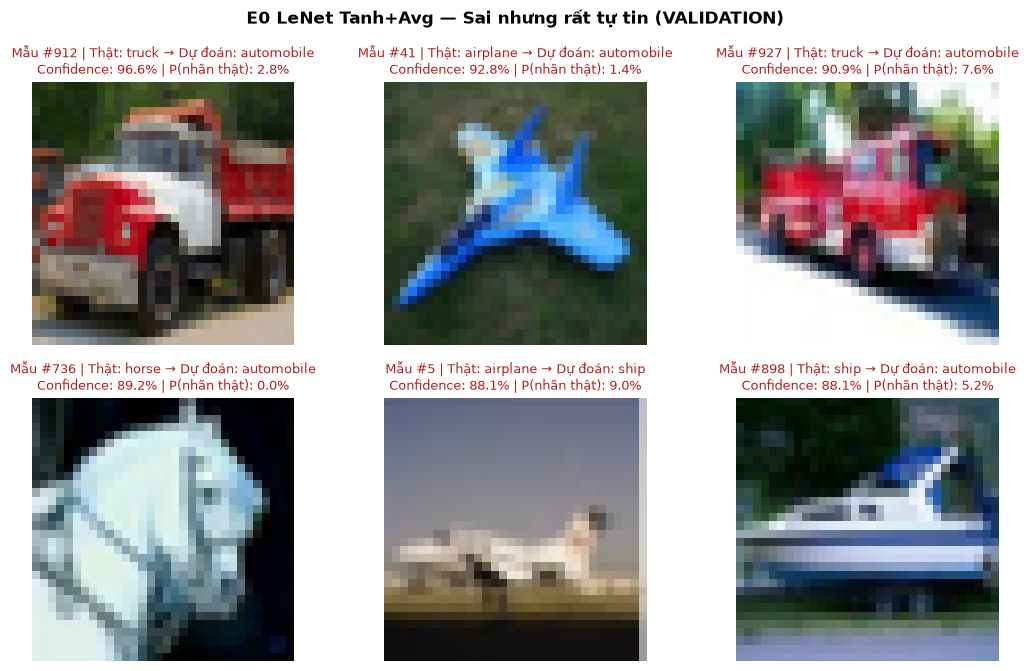

{'model': 'E0 LeNet Tanh+Avg',
 'parameters': 62006,
 'best_epoch': 11,
 'train_acc': 0.561,
 'val_acc': 0.442,
 'val_loss': 1.5683185272216797,
 'gap': 0.11900000000000005,
 'seconds': 16.52,
 'val_errors': 558}

In [20]:
run_experiment("E0 LeNet Tanh+Avg", lambda: LeNet(activation="tanh", pool="avg"))

# 11


=== E1 LeNet ReLU+Max ===
params=62,006 | augmentation=False | weight_decay=0 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.0919   | 1.8639     | 32.42%  | 1.9026   | 31.70%  | *
02/16 | 1.8022   | 1.7032     | 37.02%  | 1.7747   | 33.50%  | *
03/16 | 1.6830   | 1.5998     | 42.84%  | 1.6715   | 39.80%  | *
04/16 | 1.5706   | 1.5101     | 44.62%  | 1.5928   | 41.20%  | *
05/16 | 1.5113   | 1.4293     | 48.98%  | 1.5371   | 44.90%  | *
06/16 | 1.4523   | 1.3700     | 51.58%  | 1.5071   | 44.00%  | *
07/16 | 1.3784   | 1.3367     | 51.82%  | 1.5108   | 45.80%  | 
08/16 | 1.3413   | 1.3365     | 51.60%  | 1.5292   | 44.00%  | 
09/16 | 1.2670   | 1.2414     | 54.30%  | 1.5073   | 45.00%  | 
10/16 | 1.2292   | 1.1389     | 59.10%  | 1.4368   | 49.00%  | *
11/16 | 1.1754   | 1.0944     | 60.34%  | 1.4476   | 48.70%  | 
12/16 | 1.1056   | 1.0177     | 63.90%

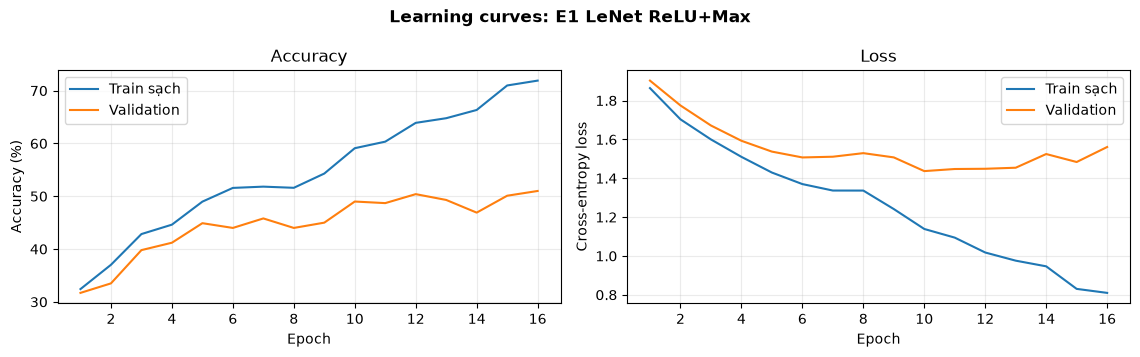


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E1 LeNet ReLU+Max ---
Sai 510/1000 mẫu (51.00%); đúng 49.00%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 33 mẫu
  airplane → ship: 29 mẫu
  deer → bird: 20 mẫu
Confidence trung bình của các mẫu sai: 46.07%


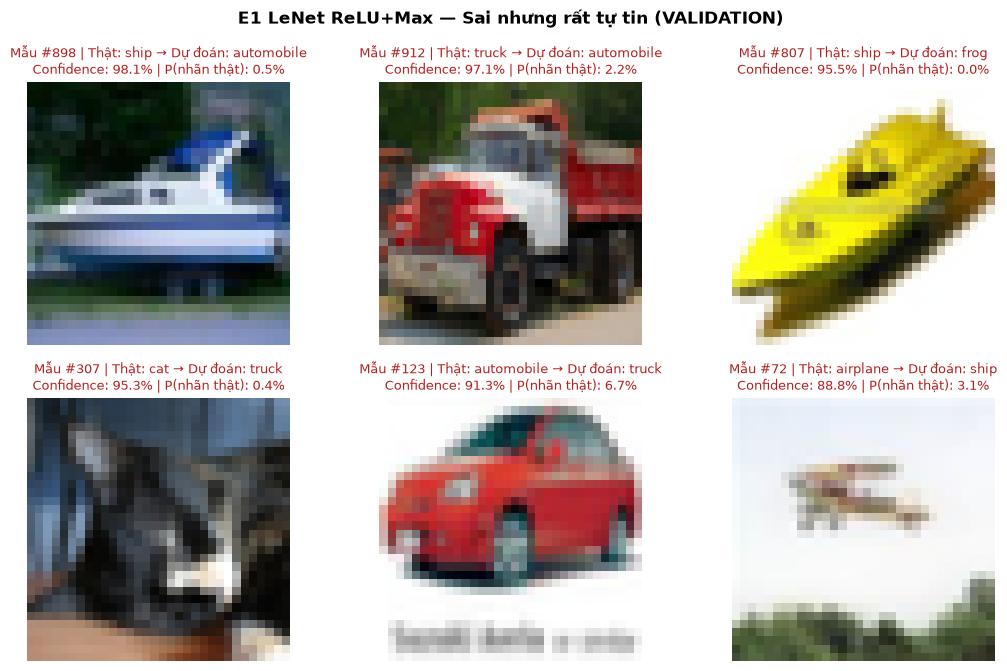

{'model': 'E1 LeNet ReLU+Max',
 'parameters': 62006,
 'best_epoch': 10,
 'train_acc': 0.591,
 'val_acc': 0.49,
 'val_loss': 1.4367545166015625,
 'gap': 0.10099999999999998,
 'seconds': 28.65,
 'val_errors': 510}

In [21]:
run_experiment("E1 LeNet ReLU+Max", lambda: LeNet(activation="relu", pool="max"))

# 12


=== E2 E1+Dropout+WD ===
params=62,006 | augmentation=False | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.1760   | 1.9396     | 31.12%  | 1.9565   | 29.50%  | *
02/16 | 1.9096   | 1.7792     | 35.20%  | 1.8210   | 32.00%  | *
03/16 | 1.7713   | 1.6467     | 38.84%  | 1.6994   | 37.20%  | *
04/16 | 1.6802   | 1.5226     | 44.00%  | 1.6065   | 41.90%  | *
05/16 | 1.6166   | 1.4781     | 45.52%  | 1.5771   | 41.60%  | *
06/16 | 1.5708   | 1.4497     | 47.76%  | 1.5519   | 45.00%  | *
07/16 | 1.5206   | 1.4101     | 48.36%  | 1.5470   | 44.00%  | *
08/16 | 1.4711   | 1.3765     | 50.04%  | 1.5309   | 44.50%  | *
09/16 | 1.4237   | 1.2788     | 53.40%  | 1.4898   | 45.70%  | *
10/16 | 1.3740   | 1.2389     | 55.50%  | 1.4638   | 48.80%  | *
11/16 | 1.3588   | 1.2134     | 57.18%  | 1.4721   | 47.60%  | 
12/16 | 1.3101   | 1.1435     | 

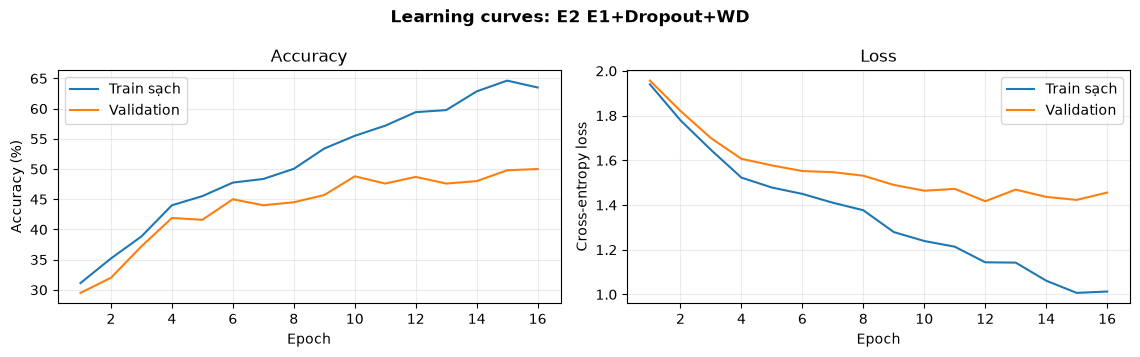


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E2 E1+Dropout+WD ---
Sai 513/1000 mẫu (51.30%); đúng 48.70%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  cat → dog: 30 mẫu
  ship → airplane: 30 mẫu
  cat → frog: 20 mẫu
Confidence trung bình của các mẫu sai: 42.79%


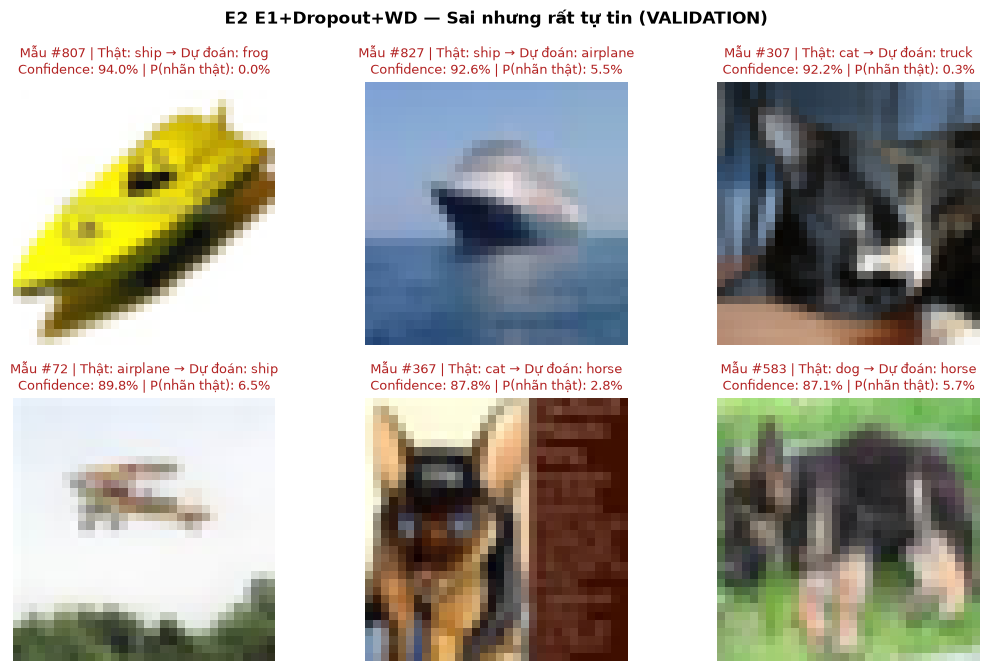

{'model': 'E2 E1+Dropout+WD',
 'parameters': 62006,
 'best_epoch': 12,
 'train_acc': 0.5942,
 'val_acc': 0.487,
 'val_loss': 1.416698884010315,
 'gap': 0.10719999999999996,
 'seconds': 26.55,
 'val_errors': 513}

In [22]:
run_experiment("E2 E1+Dropout+WD", lambda: LeNet(activation="relu", pool="max", dropout=0.3), wd=1e-3)

# 13


=== E3 E2+Aug ===
params=62,006 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.1766   | 1.9741     | 29.70%  | 1.9874   | 30.30%  | *
02/16 | 1.9601   | 1.8433     | 33.66%  | 1.8681   | 32.80%  | *
03/16 | 1.8779   | 1.7418     | 36.12%  | 1.7820   | 33.00%  | *
04/16 | 1.8031   | 1.6814     | 38.42%  | 1.7359   | 35.90%  | *
05/16 | 1.7436   | 1.6115     | 40.42%  | 1.6696   | 38.70%  | *
06/16 | 1.7126   | 1.5749     | 42.20%  | 1.6274   | 40.40%  | *
07/16 | 1.6848   | 1.5521     | 42.12%  | 1.6191   | 40.00%  | *
08/16 | 1.6586   | 1.5225     | 43.82%  | 1.6018   | 42.20%  | *
09/16 | 1.6259   | 1.4788     | 46.00%  | 1.5467   | 42.60%  | *
10/16 | 1.6025   | 1.4336     | 48.34%  | 1.4982   | 44.70%  | *
11/16 | 1.6012   | 1.4421     | 48.36%  | 1.5157   | 45.90%  | 
12/16 | 1.5654   | 1.4258     | 48.22%  

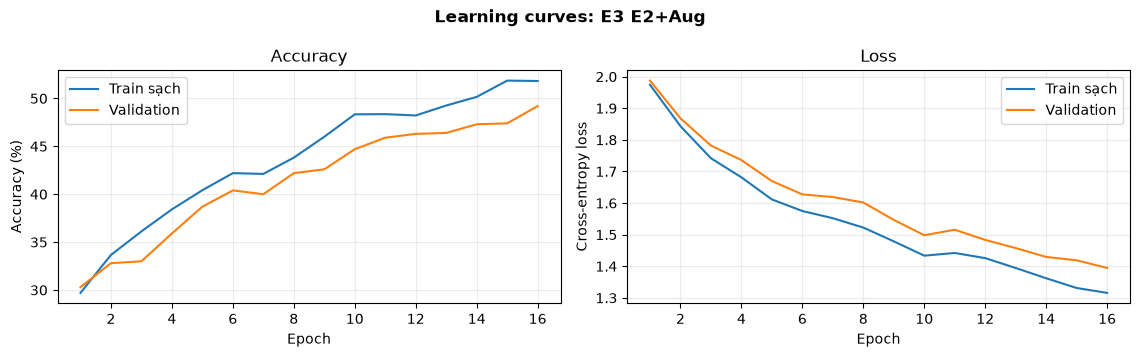


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E3 E2+Aug ---
Sai 508/1000 mẫu (50.80%); đúng 49.20%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 34 mẫu
  ship → airplane: 28 mẫu
  deer → frog: 27 mẫu
Confidence trung bình của các mẫu sai: 38.01%


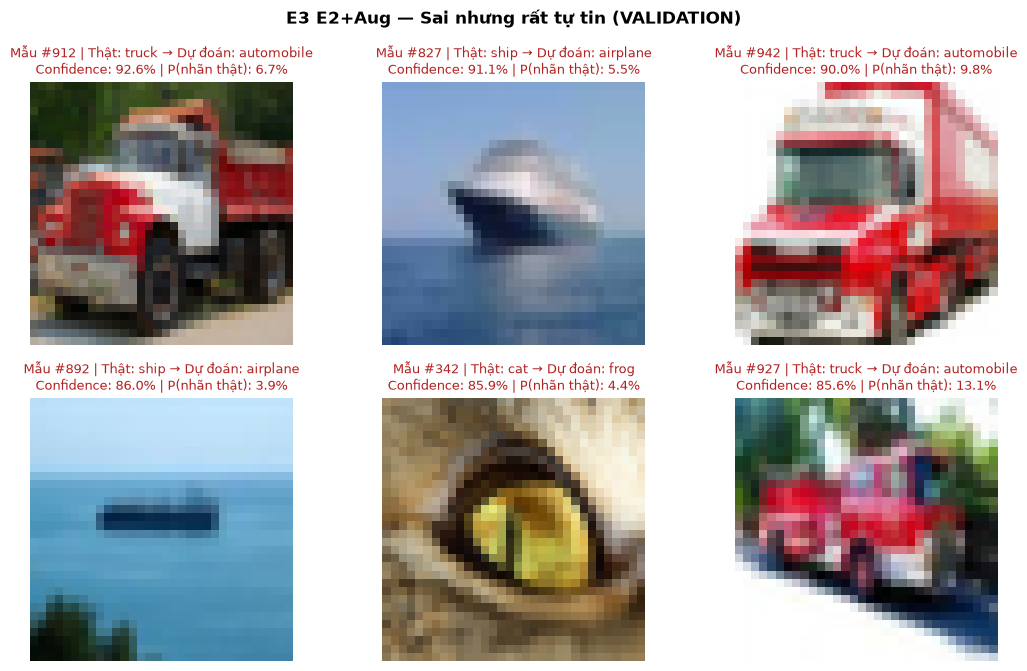

{'model': 'E3 E2+Aug',
 'parameters': 62006,
 'best_epoch': 16,
 'train_acc': 0.5182,
 'val_acc': 0.492,
 'val_loss': 1.394703751564026,
 'gap': 0.0262,
 'seconds': 72.85,
 'val_errors': 508}

In [23]:
run_experiment("E3 E2+Aug", lambda: LeNet(activation="relu", pool="max", dropout=0.3), use_aug=True, wd=1e-3)

# 14


=== E4 E3+BatchNorm ===
params=62,050 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.1447   | 1.8617     | 32.38%  | 1.8885   | 31.60%  | *
02/16 | 1.8810   | 1.6503     | 38.46%  | 1.6863   | 37.40%  | *
03/16 | 1.7769   | 1.6245     | 41.16%  | 1.6577   | 38.00%  | *
04/16 | 1.7077   | 1.5559     | 43.18%  | 1.5913   | 42.10%  | *
05/16 | 1.6739   | 1.5201     | 43.88%  | 1.5627   | 41.90%  | *
06/16 | 1.6392   | 1.4884     | 45.76%  | 1.5215   | 42.90%  | *
07/16 | 1.6164   | 1.4435     | 47.74%  | 1.4964   | 45.30%  | *
08/16 | 1.5951   | 1.4378     | 46.76%  | 1.5030   | 41.10%  | 
09/16 | 1.5639   | 1.4137     | 48.32%  | 1.4782   | 44.80%  | *
10/16 | 1.5373   | 1.3554     | 50.84%  | 1.4321   | 46.60%  | *
11/16 | 1.5446   | 1.3839     | 49.98%  | 1.4546   | 46.40%  | 
12/16 | 1.4869   | 1.3914     | 50.

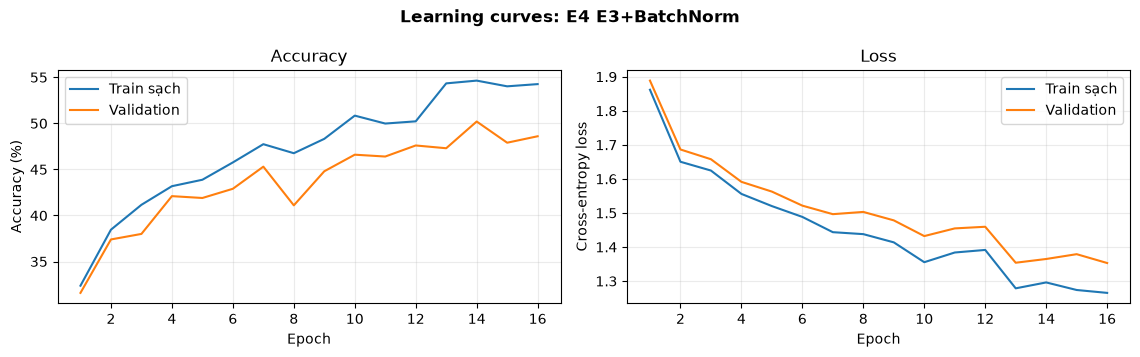


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — E4 E3+BatchNorm ---
Sai 514/1000 mẫu (51.40%); đúng 48.60%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 33 mẫu
  airplane → ship: 29 mẫu
  deer → frog: 25 mẫu
Confidence trung bình của các mẫu sai: 42.80%


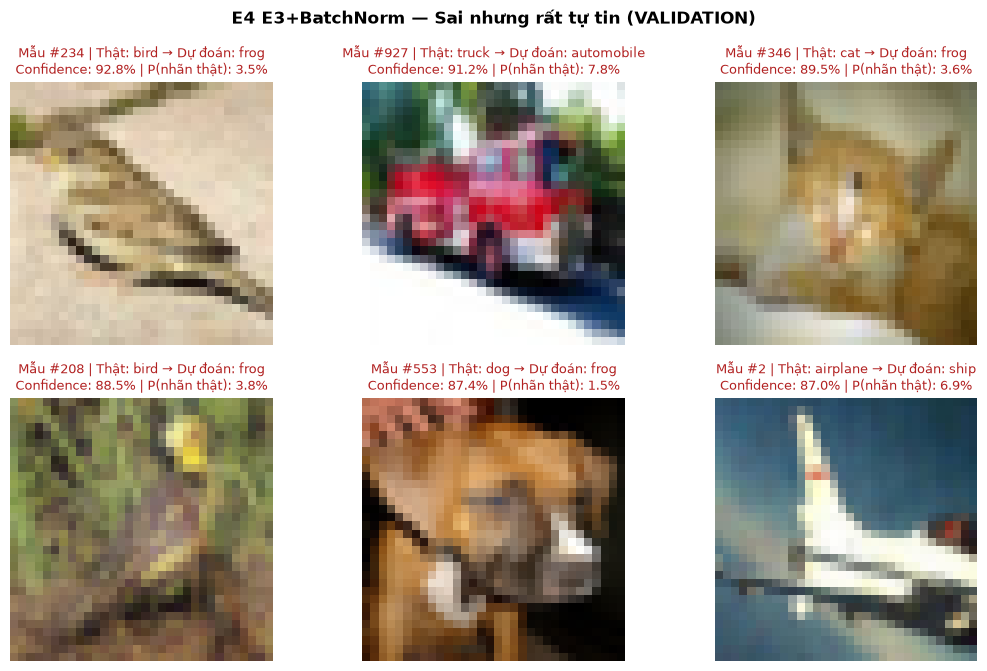

{'model': 'E4 E3+BatchNorm',
 'parameters': 62050,
 'best_epoch': 16,
 'train_acc': 0.5426,
 'val_acc': 0.486,
 'val_loss': 1.3529931421279908,
 'gap': 0.056599999999999984,
 'seconds': 88.45,
 'val_errors': 514}

In [24]:
run_experiment("E4 E3+BatchNorm", lambda: LeNet(activation="relu", pool="max", batchnorm=True, dropout=0.3), use_aug=True, wd=1e-3)

# 15


=== M1 VGG-tiny ===
params=77,114 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.0026   | 1.7264     | 33.92%  | 1.7694   | 31.30%  | *
02/16 | 1.7450   | 1.6432     | 38.90%  | 1.7093   | 38.10%  | *
03/16 | 1.6028   | 1.4174     | 47.32%  | 1.4911   | 42.30%  | *
04/16 | 1.4986   | 1.3820     | 49.52%  | 1.4563   | 44.40%  | *
05/16 | 1.4406   | 1.3260     | 50.88%  | 1.3929   | 46.90%  | *
06/16 | 1.3789   | 1.6978     | 41.74%  | 1.7654   | 40.00%  | 
07/16 | 1.3468   | 1.4360     | 48.74%  | 1.5264   | 46.30%  | 
08/16 | 1.2895   | 1.1646     | 56.84%  | 1.2543   | 53.30%  | *
09/16 | 1.2446   | 1.1660     | 57.68%  | 1.2768   | 53.80%  | 
10/16 | 1.2076   | 1.2662     | 55.48%  | 1.3462   | 52.20%  | 
11/16 | 1.2044   | 1.1257     | 58.48%  | 1.2512   | 53.80%  | *
12/16 | 1.1509   | 1.0829     | 60.54%  |

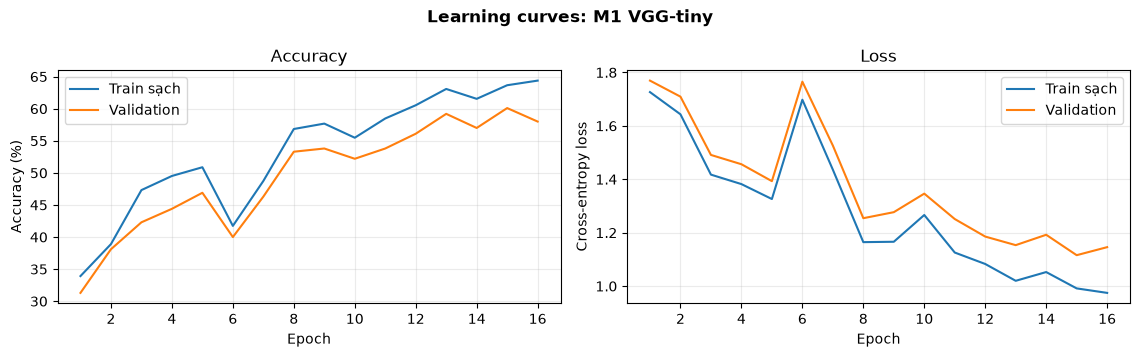


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M1 VGG-tiny ---
Sai 399/1000 mẫu (39.90%); đúng 60.10%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  cat → dog: 41 mẫu
  truck → automobile: 24 mẫu
  airplane → automobile: 20 mẫu
Confidence trung bình của các mẫu sai: 51.39%


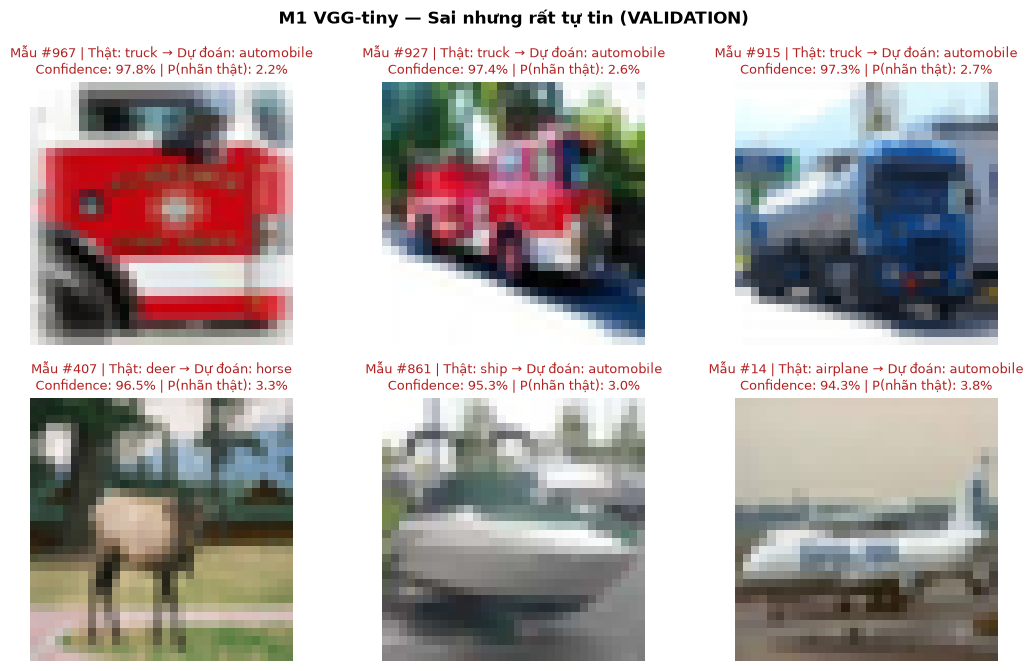

{'model': 'M1 VGG-tiny',
 'parameters': 77114,
 'best_epoch': 15,
 'train_acc': 0.6366,
 'val_acc': 0.601,
 'val_loss': 1.1157837796211243,
 'gap': 0.035600000000000076,
 'seconds': 172.19,
 'val_errors': 399}

In [25]:
run_experiment("M1 VGG-tiny", lambda: VGGTiny(), use_aug=True, wd=1e-3)

# 16


=== M2 Inception-tiny ===
params=27,850 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 2.0439   | 1.8650     | 29.66%  | 1.8758   | 28.30%  | *
02/16 | 1.8027   | 1.6752     | 39.16%  | 1.6966   | 37.30%  | *
03/16 | 1.6782   | 1.5299     | 43.62%  | 1.5813   | 40.90%  | *
04/16 | 1.5821   | 1.4545     | 46.80%  | 1.5028   | 45.30%  | *
05/16 | 1.5223   | 1.3985     | 47.82%  | 1.4544   | 45.50%  | *
06/16 | 1.4580   | 1.4465     | 47.84%  | 1.5231   | 45.00%  | 
07/16 | 1.4300   | 1.3006     | 52.80%  | 1.3582   | 50.30%  | *
08/16 | 1.3782   | 1.2323     | 54.56%  | 1.2868   | 53.90%  | *
09/16 | 1.3298   | 1.1915     | 56.36%  | 1.2668   | 52.30%  | *
10/16 | 1.3238   | 1.1772     | 56.40%  | 1.2592   | 53.10%  | *
11/16 | 1.2883   | 1.1806     | 57.42%  | 1.2771   | 53.30%  | 
12/16 | 1.2828   | 1.1228     | 6

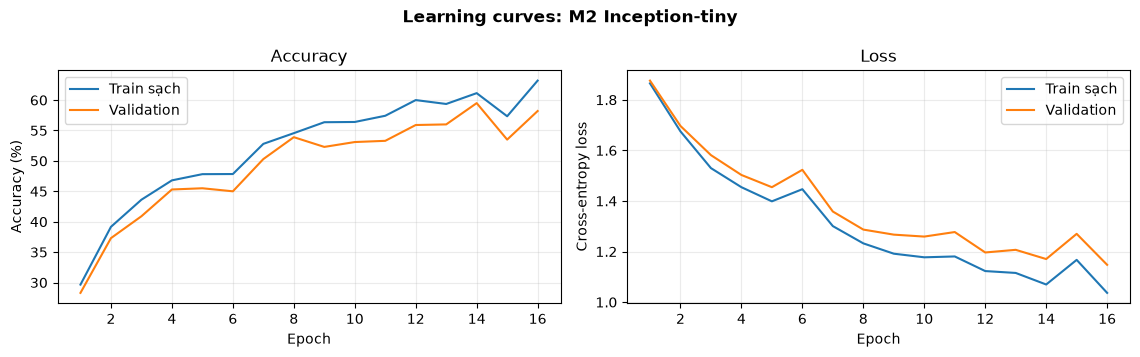


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M2 Inception-tiny ---
Sai 418/1000 mẫu (41.80%); đúng 58.20%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  cat → dog: 31 mẫu
  truck → automobile: 25 mẫu
  horse → dog: 24 mẫu
Confidence trung bình của các mẫu sai: 46.05%


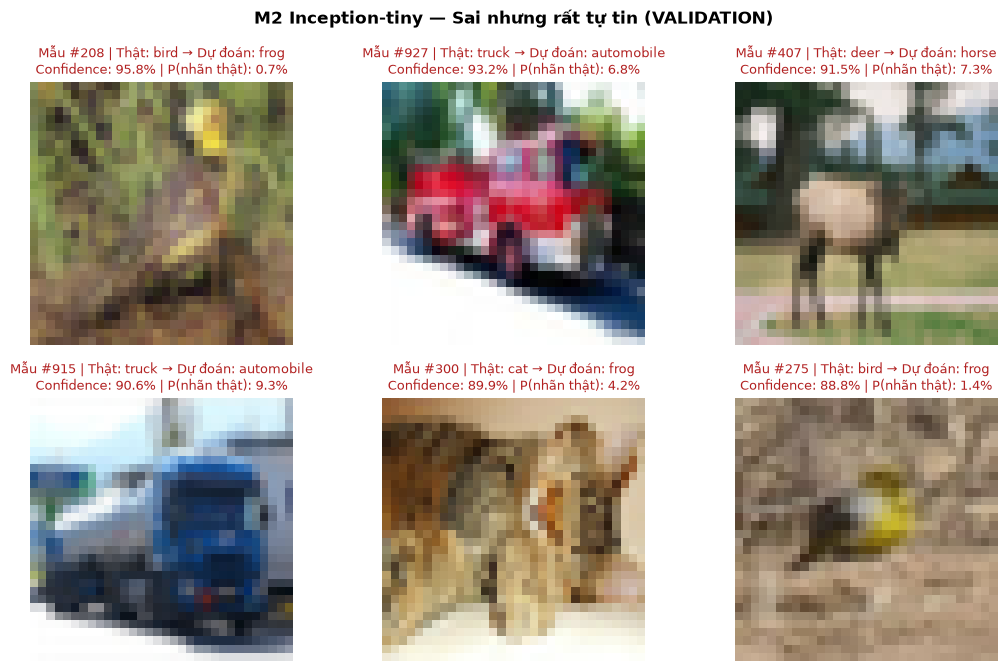

{'model': 'M2 Inception-tiny',
 'parameters': 27850,
 'best_epoch': 16,
 'train_acc': 0.632,
 'val_acc': 0.582,
 'val_loss': 1.1475320749282838,
 'gap': 0.050000000000000044,
 'seconds': 389.58,
 'val_errors': 418}

In [26]:
run_experiment("M2 Inception-tiny", lambda: InceptionTiny(), use_aug=True, wd=1e-3)

# 17


=== M3 ResNet-tiny ===
params=170,586 | augmentation=True | weight_decay=0.001 | lr=0.001 | epochs=16
epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | best
------------------------------------------------------------------------------
01/16 | 1.9074   | 1.8417     | 31.16%  | 1.9065   | 29.80%  | *
02/16 | 1.6701   | 1.6354     | 40.74%  | 1.6842   | 39.50%  | *
03/16 | 1.5391   | 1.4997     | 44.28%  | 1.5463   | 43.10%  | *
04/16 | 1.4274   | 1.4580     | 47.02%  | 1.5751   | 42.90%  | 
05/16 | 1.3627   | 1.3942     | 47.16%  | 1.4614   | 44.00%  | *
06/16 | 1.2863   | 1.3387     | 50.48%  | 1.4486   | 47.20%  | *
07/16 | 1.2301   | 1.1051     | 60.20%  | 1.2195   | 55.20%  | *
08/16 | 1.1770   | 1.1576     | 57.28%  | 1.2826   | 53.10%  | 
09/16 | 1.1445   | 1.2029     | 56.76%  | 1.3239   | 51.60%  | 
10/16 | 1.1018   | 1.0703     | 61.24%  | 1.2263   | 57.00%  | 
11/16 | 1.0604   | 1.0671     | 61.64%  | 1.2407   | 55.90%  | 
12/16 | 1.0456   | 1.1112     | 60.74%

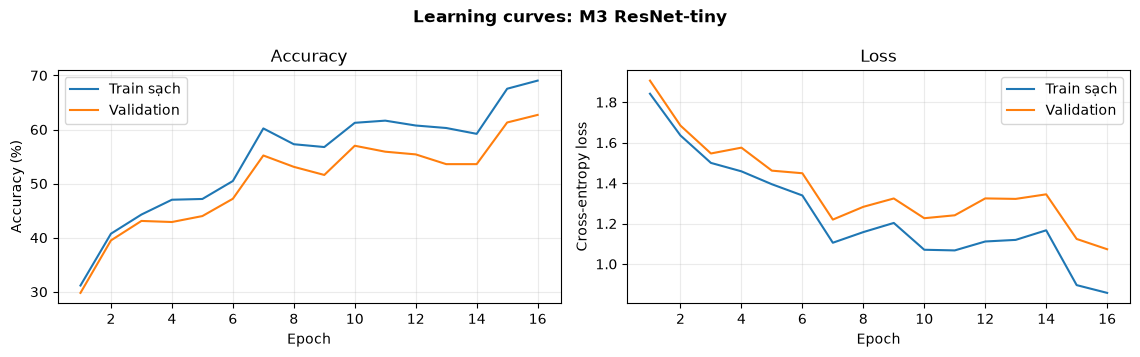


--- PHÂN TÍCH MẪU SAI TRÊN VALIDATION — M3 ResNet-tiny ---
Sai 373/1000 mẫu (37.30%); đúng 62.70%.
Các cặp nhầm lẫn phổ biến (lớp thật → lớp dự đoán):
  dog → cat: 27 mẫu
  airplane → ship: 15 mẫu
  automobile → truck: 14 mẫu
Confidence trung bình của các mẫu sai: 53.99%


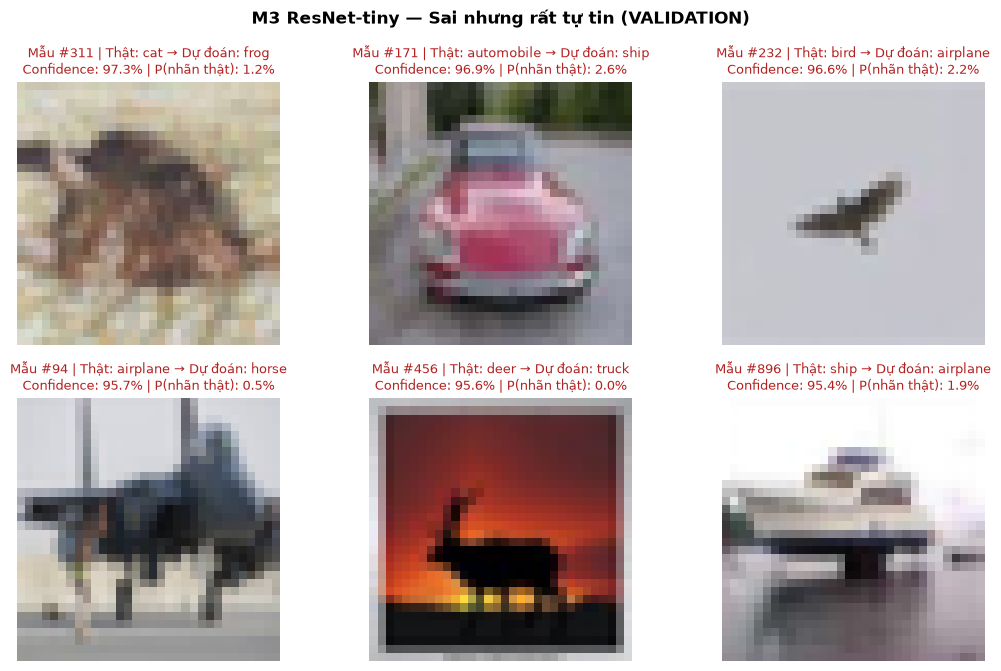

{'model': 'M3 ResNet-tiny',
 'parameters': 170586,
 'best_epoch': 16,
 'train_acc': 0.6904,
 'val_acc': 0.627,
 'val_loss': 1.0729182295799256,
 'gap': 0.06340000000000001,
 'seconds': 246.11,
 'val_errors': 373}

In [27]:
run_experiment("M3 ResNet-tiny", lambda: ResNetTiny(), use_aug=True, wd=1e-3)

# Tổng hợp, đánh giá Test và xuất

,model,parameters,best_epoch,train_acc,val_acc,val_loss,gap,seconds,val_errors
0,M3 ResNet-tiny,170586,16,0.6904,0.627,1.072918,0.0634,246.11,373
1,M1 VGG-tiny,77114,15,0.6366,0.601,1.115784,0.0356,172.19,399
2,M2 Inception-tiny,27850,16,0.6320,0.582,1.147532,0.0500,389.58,418
3,E3 E2+Aug,62006,16,0.5182,0.492,1.394704,0.0262,72.85,508
4,E1 LeNet ReLU+Max,62006,10,0.5910,0.490,1.436755,0.1010,28.65,510
5,E2 E1+Dropout+WD,62006,12,0.5942,0.487,1.416699,0.1072,26.55,513
6,E4 E3+BatchNorm,62050,16,0.5426,0.486,1.352993,0.0566,88.45,514
7,E0 LeNet Tanh+Avg,62006,11,0.5610,0.442,1.568319,0.1190,16.52,558


Mô hình tốt nhất theo validation: M3 ResNet-tiny

=== KẾT QUẢ TEST CUỐI (M3 ResNet-tiny) ===
Test Loss: 1.0784 | Test Accuracy: 60.30% (2000 mẫu)

Classification Report:
               precision    recall  f1-score   support

    airplane       0.52      0.78      0.62       200
  automobile       0.92      0.64      0.76       200
        bird       0.48      0.45      0.46       200
         cat       0.39      0.44      0.42       200
        deer       0.53      0.56      0.54       200
         dog       0.64      0.28      0.39       200
        frog       0.64      0.71      0.68       200
       horse       0.66      0.71      0.69       200
        ship       0.61      0.73      0.66       200
       truck       0.82      0.74      0.78       200

    accuracy                           0.60      2000
   macro avg       0.62      0.60      0.60      2000
weighted avg       0.62      0.60      0.60      2000



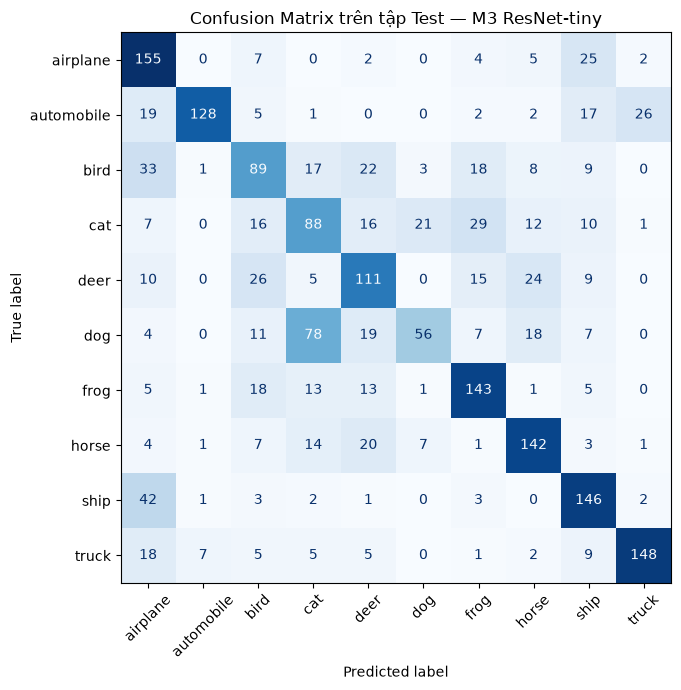

In [28]:
summary_df = pd.DataFrame(RESULTS).sort_values(by=["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True)
display(summary_df)

best_name = summary_df.loc[0, "model"]
best_model = BEST_MODELS[best_name].to(DEVICE)
print(f"Mô hình tốt nhất theo validation: {best_name}")

test_res = test_model(best_model, test_loader, criterion, DEVICE, CLASS_NAMES)
print(f"\n=== KẾT QUẢ TEST CUỐI ({best_name}) ===")
print(f"Test Loss: {test_res['loss']:.4f} | Test Accuracy: {test_res['accuracy']:.2%} ({test_res['n_samples']} mẫu)")
print("\nClassification Report:\n", test_res["classification_report"])

fig, ax = plt.subplots(figsize=(8.5, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=test_res["confusion_matrix"], display_labels=CLASS_NAMES)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion Matrix trên tập Test — {best_name}")
plt.tight_layout()
plt.show()

In [30]:
class KaggleTestDataset(Dataset):
    def __init__(self, img_ids, folder, mean, std):
        self.img_ids = img_ids
        self.folder = folder
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        path = os.path.join(self.folder, f"{self.img_ids[idx]}.png")
        with Image.open(path) as img:
            arr = np.asarray(img.convert("RGB"), dtype=np.uint8)
        tensor = torch.tensor(arr, dtype=torch.float32).permute(2, 0, 1) / 255.0
        return (tensor - self.mean) / self.std

test_kaggle_folder = os.path.join(DATA_DIR, "test")
if os.path.isdir(os.path.join(test_kaggle_folder, "test")):
    test_kaggle_folder = os.path.join(test_kaggle_folder, "test")

sub_df = pd.read_csv(os.path.join(DATA_DIR, "sampleSubmission.csv"))
kaggle_ds = KaggleTestDataset(sub_df["id"].to_numpy(), test_kaggle_folder, mu, sigma)
kaggle_loader = DataLoader(kaggle_ds, batch_size=256, shuffle=False, num_workers=0)

best_model.eval()
preds_all = []
with torch.inference_mode():
    for xb in kaggle_loader:
        preds = best_model(xb.to(DEVICE)).argmax(dim=1).cpu().tolist()
        preds_all.extend(preds)

sub_df["label"] = [CLASS_NAMES[p] for p in preds_all]
sub_df.to_csv("submission.csv", index=False)
print("Đã xuất file submission.csv:", sub_df.shape)

Đã xuất file submission.csv: (300000, 2)
